In [4]:
# MÓDULO 2 — CONVERSÃO DAS MEDIDAS PARA O SISTEMA MÉTRICO
# Converte distância de pés para metros, altura de polegadas para
# centímetros e peso de libras para quilogramas.
# Arredonda as medidas convertidas para duas casas decimais.
# Preserva as colunas originais e não altera os CSVs da coleta.
# Exibe as tabelas sem precisar da biblioteca jinja2.

from pathlib import Path
import pandas as pd

pasta_arremessos = Path("dados/arremessos")
pasta_perfis = Path("dados/perfis_por_temporada")

arquivos_arremessos = sorted(pasta_arremessos.glob("*/*.csv"))
arquivos_perfis = sorted(pasta_perfis.glob("*.csv"))

if not arquivos_arremessos:
    raise FileNotFoundError("Nenhum arquivo de arremessos encontrado.")

if not arquivos_perfis:
    raise FileNotFoundError("Nenhum arquivo de perfis físicos encontrado.")

# Carrega os eventos, preservando os zeros iniciais dos códigos de jogo.
df_arremessos = pd.concat(
    [
        pd.read_csv(
            arquivo,
            dtype={"GAME_ID": "string", "SEASON": "string"}
        )
        for arquivo in arquivos_arremessos
    ],
    ignore_index=True
)

df_perfis = pd.concat(
    [
        pd.read_csv(arquivo, dtype={"SEASON": "string"})
        for arquivo in arquivos_perfis
    ],
    ignore_index=True
)

# Valores ausentes continuam ausentes.
# Texto inesperado interrompe a conversão para permitir investigação.
df_arremessos["DISTANCIA_M"] = (
    pd.to_numeric(df_arremessos["SHOT_DISTANCE"], errors="raise")
    * 0.3048
).round(2)

df_perfis["ALTURA_CM"] = (
    pd.to_numeric(df_perfis["PLAYER_HEIGHT_INCHES"], errors="raise")
    * 2.54
).round(2)

df_perfis["PESO_KG"] = (
    pd.to_numeric(df_perfis["PLAYER_WEIGHT"], errors="raise")
    * 0.45359237
).round(2)

# A formatação abaixo afeta apenas a exibição dentro deste bloco.
# Valores ausentes aparecem como NaN.
with pd.option_context("display.float_format", "{:.2f}".format):
    print("DISTÂNCIAS — PÉS E METROS")

    display(
        df_arremessos[
            ["PLAYER_NAME", "SEASON", "SHOT_DISTANCE", "DISTANCIA_M"]
        ].head(10)
    )

    print("PERFIS — MEDIDAS ORIGINAIS E CONVERTIDAS")

    display(
        df_perfis[
            [
                "PLAYER_NAME",
                "SEASON",
                "PLAYER_HEIGHT_INCHES",
                "ALTURA_CM",
                "PLAYER_WEIGHT",
                "PESO_KG"
            ]
        ].head(10)
    )

print("VALORES AUSENTES APÓS A CONVERSÃO")
print("Distância:", df_arremessos["DISTANCIA_M"].isna().sum())
print("Altura:", df_perfis["ALTURA_CM"].isna().sum())
print("Peso:", df_perfis["PESO_KG"].isna().sum())

DISTÂNCIAS — PÉS E METROS


,PLAYER_NAME,SEASON,SHOT_DISTANCE,DISTANCIA_M
0,Andrew Bogut,2015-16,0,0.00
1,Andrew Bogut,2015-16,0,0.00
2,Andrew Bogut,2015-16,2,0.61
3,Andrew Bogut,2015-16,1,0.30
4,Andrew Bogut,2015-16,1,0.30
5,Andrew Bogut,2015-16,7,2.13
6,Andrew Bogut,2015-16,2,0.61
7,Andrew Bogut,2015-16,0,0.00
8,Andrew Bogut,2015-16,6,1.83
9,Andrew Bogut,2015-16,0,0.00


PERFIS — MEDIDAS ORIGINAIS E CONVERTIDAS


,PLAYER_NAME,SEASON,PLAYER_HEIGHT_INCHES,ALTURA_CM,PLAYER_WEIGHT,PESO_KG
0,Aaron Brooks,2015-16,72,182.88,161,73.03
1,Aaron Gordon,2015-16,81,205.74,220,99.79
2,Aaron Harrison,2015-16,78,198.12,210,95.25
3,Adreian Payne,2015-16,82,208.28,237,107.50
4,Al Horford,2015-16,82,208.28,245,111.13
5,Al Jefferson,2015-16,82,208.28,289,131.09
6,Al-Farouq Aminu,2015-16,81,205.74,215,97.52
7,Alan Anderson,2015-16,78,198.12,220,99.79
8,Alan Williams,2015-16,80,203.20,260,117.93
9,Alec Burks,2015-16,78,198.12,214,97.07


VALORES AUSENTES APÓS A CONVERSÃO
Distância: 341
Altura: 0
Peso: 0


In [5]:
# MÓDULO 3 — INVESTIGAÇÃO DAS DISTÂNCIAS AUSENTES
# Identifica os eventos sem distância e examina sua distribuição.
# Confere a disponibilidade das coordenadas, sem reconstruir distâncias.
# Não modifica os dados nem exclui registros.

import numpy as np
import pandas as pd

mascara_ausentes = df_arremessos["DISTANCIA_M"].isna()

arremessos_sem_distancia = df_arremessos.loc[
    mascara_ausentes
].copy()

total_eventos = len(df_arremessos)
total_ausentes = len(arremessos_sem_distancia)

percentual_ausentes = (
    100 * total_ausentes / total_eventos
    if total_eventos
    else 0
)

print("Total de tentativas:", total_eventos)
print("Tentativas sem distância:", total_ausentes)
print(f"Percentual sem distância: {percentual_ausentes:.4f}%")

if total_ausentes == 0:
    print("Não há distâncias ausentes para investigar.")

else:
    # Calcula quantidade e percentual de ausentes dentro de cada grupo.
    def resumir_distancias_ausentes(colunas):
        resumo = (
            df_arremessos
            .groupby(colunas, dropna=False)
            .agg(
                TOTAL_TENTATIVAS=("DISTANCIA_M", "size"),
                SEM_DISTANCIA=(
                    "DISTANCIA_M",
                    lambda valores: valores.isna().sum()
                )
            )
            .reset_index()
        )

        resumo["PERCENTUAL_AUSENTE"] = (
            100
            * resumo["SEM_DISTANCIA"]
            / resumo["TOTAL_TENTATIVAS"]
        ).round(2)

        return (
            resumo.loc[resumo["SEM_DISTANCIA"].gt(0)]
            .sort_values("SEM_DISTANCIA", ascending=False)
            .reset_index(drop=True)
        )

    resumo_ausentes_temporada = resumir_distancias_ausentes(
        ["SEASON"]
    )

    resumo_ausentes_tipo = resumir_distancias_ausentes(
        ["ACTION_TYPE"]
    )

    resumo_ausentes_jogador = resumir_distancias_ausentes(
        ["PLAYER_ID", "PLAYER_NAME"]
    )

    print("\nDISTÂNCIAS AUSENTES POR TEMPORADA")
    display(resumo_ausentes_temporada)

    print("\nDISTÂNCIAS AUSENTES POR TIPO DE MOVIMENTO")
    display(resumo_ausentes_tipo)

    print("\n20 JOGADORES COM MAIS DISTÂNCIAS AUSENTES")
    display(resumo_ausentes_jogador.head(20))

    # Coordenadas numéricas e finitas são candidatas à investigação.
    # Sua presença, sozinha, não comprova que a localização esteja correta.
    coordenada_x = pd.to_numeric(
        arremessos_sem_distancia["LOC_X"], errors="coerce"
    )
    coordenada_y = pd.to_numeric(
        arremessos_sem_distancia["LOC_Y"], errors="coerce"
    )

    coordenadas_disponiveis = (
        coordenada_x.notna()
        & coordenada_y.notna()
        & ~coordenada_x.isin([np.inf, -np.inf])
        & ~coordenada_y.isin([np.inf, -np.inf])
    )

    coordenadas_na_origem = (
        coordenadas_disponiveis
        & coordenada_x.eq(0)
        & coordenada_y.eq(0)
    )

    arremessos_sem_distancia["COORDENADAS_NUMERICAS_FINITAS"] = (
        coordenadas_disponiveis
    )

    print("\nDISPONIBILIDADE DAS COORDENADAS")
    print(
        "Com as duas coordenadas numéricas e finitas:",
        int(coordenadas_disponiveis.sum())
    )
    print(
        "Com alguma coordenada ausente, não numérica ou infinita:",
        int((~coordenadas_disponiveis).sum())
    )
    print(
        "Com ambas as coordenadas iguais a zero:",
        int(coordenadas_na_origem.sum())
    )

    print("\nTIPO DE ARREMESSO E RESULTADO DOS EVENTOS SEM DISTÂNCIA")
    display(
        arremessos_sem_distancia
        .groupby(
            ["SHOT_TYPE", "EVENT_TYPE"],
            dropna=False
        )
        .size()
        .reset_index(name="QUANTIDADE")
        .sort_values("QUANTIDADE", ascending=False)
    )

    print("\nAMOSTRA DOS EVENTOS SEM DISTÂNCIA")
    display(
        arremessos_sem_distancia[
            [
                "SEASON",
                "GAME_ID",
                "GAME_EVENT_ID",
                "PLAYER_NAME",
                "ACTION_TYPE",
                "SHOT_TYPE",
                "SHOT_MADE_FLAG",
                "SHOT_DISTANCE",
                "LOC_X",
                "LOC_Y",
                "PERIOD",
                "MINUTES_REMAINING",
                "SECONDS_REMAINING",
                "COORDENADAS_NUMERICAS_FINITAS"
            ]
        ].head(30)
    )

Total de tentativas: 2100596
Tentativas sem distância: 341
Percentual sem distância: 0.0162%

DISTÂNCIAS AUSENTES POR TEMPORADA


,SEASON,TOTAL_TENTATIVAS,SEM_DISTANCIA,PERCENTUAL_AUSENTE
0,2016-17,210114,185,0.09
1,2015-16,208049,156,0.07



DISTÂNCIAS AUSENTES POR TIPO DE MOVIMENTO


,ACTION_TYPE,TOTAL_TENTATIVAS,SEM_DISTANCIA,PERCENTUAL_AUSENTE
0,Jump Shot,747857,323,0.04
1,Step Back Jump shot,83349,10,0.01
2,Running Jump Shot,30048,3,0.01
3,Pullup Jump shot,220011,2,0.00
4,Running Pull-Up Jump Shot,15856,2,0.01
5,Layup Shot,97234,1,0.00



20 JOGADORES COM MAIS DISTÂNCIAS AUSENTES


,PLAYER_ID,PLAYER_NAME,TOTAL_TENTATIVAS,SEM_DISTANCIA,PERCENTUAL_AUSENTE
0,200755,JJ Redick,4574,16,0.35
1,201601,Luc Mbah a Moute,953,13,1.36
2,202325,Wesley Johnson,1211,12,0.99
3,201156,Nick Young,1502,12,0.80
4,101145,Monta Ellis,1578,8,0.51
5,202331,Paul George,10932,7,0.06
6,2037,Jamal Crawford,2993,7,0.23
7,201573,Jerryd Bayless,961,5,0.52
8,203903,Jordan Clarkson,9698,5,0.05
9,1627742,Brandon Ingram,7541,5,0.07



DISPONIBILIDADE DAS COORDENADAS
Com as duas coordenadas numéricas e finitas: 0
Com alguma coordenada ausente, não numérica ou infinita: 341
Com ambas as coordenadas iguais a zero: 0

TIPO DE ARREMESSO E RESULTADO DOS EVENTOS SEM DISTÂNCIA


,SHOT_TYPE,EVENT_TYPE,QUANTIDADE
2,3PT Field Goal,Missed Shot,221
1,3PT Field Goal,Made Shot,119
0,2PT Field Goal,Missed Shot,1



AMOSTRA DOS EVENTOS SEM DISTÂNCIA


,SEASON,GAME_ID,GAME_EVENT_ID,PLAYER_NAME,ACTION_TYPE,SHOT_TYPE,SHOT_MADE_FLAG,SHOT_DISTANCE,LOC_X,LOC_Y,PERIOD,MINUTES_REMAINING,SECONDS_REMAINING,COORDENADAS_NUMERICAS_FINITAS
458,2015-16,0021500338,164,Marvin Williams,Jump Shot,3PT Field Goal,0,NaN,NaN,NaN,2,8,56,False
1675,2015-16,0021500745,320,Chris Paul,Jump Shot,3PT Field Goal,0,NaN,NaN,NaN,3,4,56,False
2998,2015-16,0021500491,121,Charlie Villanueva,Jump Shot,3PT Field Goal,1,NaN,NaN,NaN,2,11,6,False
4411,2015-16,0021500333,362,Gerald Green,Jump Shot,3PT Field Goal,1,NaN,NaN,NaN,3,1,15,False
7735,2015-16,0021500127,328,Monta Ellis,Jump Shot,3PT Field Goal,0,NaN,NaN,NaN,3,0,9,False
7850,2015-16,0021500333,435,Monta Ellis,Jump Shot,3PT Field Goal,1,NaN,NaN,NaN,4,6,2,False
7892,2015-16,0021500371,339,Monta Ellis,Jump Shot,3PT Field Goal,1,NaN,NaN,NaN,3,3,25,False
7962,2015-16,0021500459,244,Monta Ellis,Jump Shot,3PT Field Goal,0,NaN,NaN,NaN,2,0,1,False
8199,2015-16,0021500709,97,Monta Ellis,Jump Shot,3PT Field Goal,1,NaN,NaN,NaN,1,1,42,False
8530,2015-16,0021501082,305,Monta Ellis,Jump Shot,3PT Field Goal,0,NaN,NaN,NaN,3,7,12,False


In [6]:
# MÓDULO 4 — SEPARAÇÃO DOS EVENTOS PARA ANÁLISES DE DISTÂNCIA
# Preserva todos os eventos na base principal.
# Guarda os identificadores dos eventos sem distância.
# Cria uma base específica para análises que precisam dessa medida.

df_arremessos["DISTANCIA_DISPONIVEL"] = (
    df_arremessos["DISTANCIA_M"].notna()
)

ids_sem_distancia = df_arremessos.loc[
    ~df_arremessos["DISTANCIA_DISPONIVEL"],
    ["GAME_ID", "GAME_EVENT_ID", "PLAYER_ID", "SEASON"]
].copy()

df_arremessos_com_distancia = df_arremessos.loc[
    df_arremessos["DISTANCIA_DISPONIVEL"]
].copy()

print("Base completa:", len(df_arremessos))
print("Eventos sem distância:", len(ids_sem_distancia))
print("Base para analisar distâncias:", len(df_arremessos_com_distancia))



Base completa: 2100596
Eventos sem distância: 341
Base para analisar distâncias: 2100255


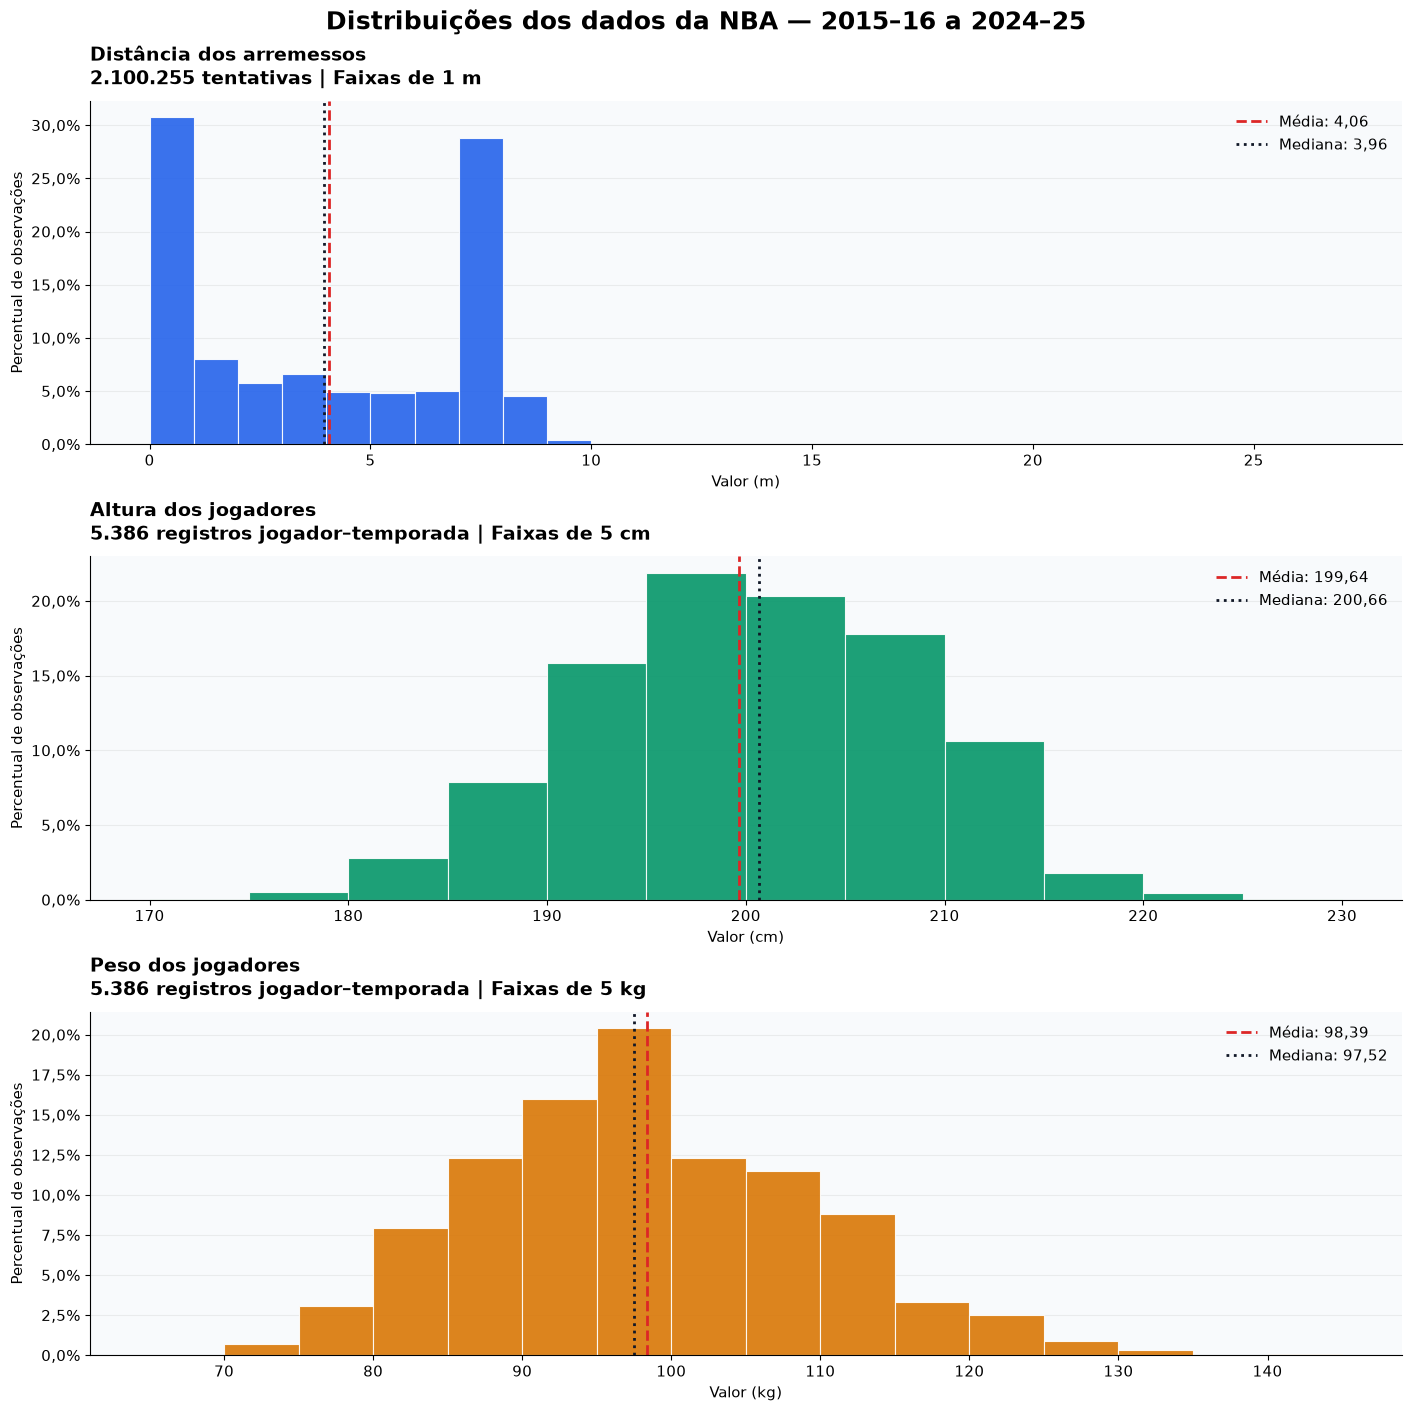


RESUMO ESTATÍSTICO


,VARIÁVEL,UNIDADE,OBSERVAÇÕES,MÍNIMO,1º QUARTIL,MEDIANA,MÉDIA,3º QUARTIL,MÁXIMO,DESVIO PADRÃO
0,Distância dos arremessos,m,2.100.255,"0,00","0,61","3,96","4,06","7,32","26,82","3,20"
1,Altura dos jogadores,cm,5.386,"170,18","193,04","200,66","199,64","205,74","228,60","8,48"
2,Peso dos jogadores,kg,5.386,"68,04","90,72","97,52","98,39","106,59","141,07","11,16"



DISTÂNCIA DOS ARREMESSOS
Valores ausentes ou inválidos fora desta distribuição: 0


,Faixa (m),Quantidade,Percentual,Percentual acumulado
0,"0,00 a < 1,00",645.806,"30,75%","30,75%"
1,"1,00 a < 2,00",168.600,"8,03%","38,78%"
2,"2,00 a < 3,00",120.539,"5,74%","44,52%"
3,"3,00 a < 4,00",137.734,"6,56%","51,07%"
4,"4,00 a < 5,00",102.275,"4,87%","55,94%"
5,"5,00 a < 6,00",102.021,"4,86%","60,80%"
6,"6,00 a < 7,00",105.586,"5,03%","65,83%"
7,"7,00 a < 8,00",604.922,"28,80%","94,63%"
8,"8,00 a < 9,00",95.118,"4,53%","99,16%"
9,"9,00 a < 10,00",9.209,"0,44%","99,60%"



ALTURA DOS JOGADORES
Valores ausentes ou inválidos fora desta distribuição: 0


,Faixa (cm),Quantidade,Percentual,Percentual acumulado
0,"170,00 a < 175,00",3,"0,06%","0,06%"
1,"175,00 a < 180,00",29,"0,54%","0,59%"
2,"180,00 a < 185,00",150,"2,78%","3,38%"
3,"185,00 a < 190,00",424,"7,87%","11,25%"
4,"190,00 a < 195,00",855,"15,87%","27,13%"
5,"195,00 a < 200,00",1.179,"21,89%","49,02%"
6,"200,00 a < 205,00",1.094,"20,31%","69,33%"
7,"205,00 a < 210,00",957,"17,77%","87,10%"
8,"210,00 a < 215,00",571,"10,60%","97,70%"
9,"215,00 a < 220,00",97,"1,80%","99,50%"



PESO DOS JOGADORES
Valores ausentes ou inválidos fora desta distribuição: 0


,Faixa (kg),Quantidade,Percentual,Percentual acumulado
0,"65,00 a < 70,00",1,"0,02%","0,02%"
1,"70,00 a < 75,00",36,"0,67%","0,69%"
2,"75,00 a < 80,00",164,"3,04%","3,73%"
3,"80,00 a < 85,00",427,"7,93%","11,66%"
4,"85,00 a < 90,00",661,"12,27%","23,93%"
5,"90,00 a < 95,00",860,"15,97%","39,90%"
6,"95,00 a < 100,00",1.099,"20,40%","60,30%"
7,"100,00 a < 105,00",663,"12,31%","72,61%"
8,"105,00 a < 110,00",618,"11,47%","84,09%"
9,"110,00 a < 115,00",474,"8,80%","92,89%"



Distâncias: a base utilizada já exclui os eventos sem distância.
Altura e peso: cada jogador pode aparecer em várias temporadas; as distribuições não representam jogadores únicos.
As faixas agrupam os dados para visualização; não representam critérios de exclusão.


In [7]:
# MÓDULO 5 — DISTRIBUIÇÕES DE DISTÂNCIA, ALTURA E PESO
# Apresenta histogramas, resumos estatísticos e tabelas por faixa.
# Distância: cada observação representa uma tentativa de arremesso.
# Altura e peso: cada observação representa um jogador–temporada.
# Não altera as bases e não aplica cortes nos valores extremos.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

variaveis_necessarias = [
    "df_arremessos_com_distancia",
    "df_perfis"
]

faltantes = [
    nome for nome in variaveis_necessarias
    if nome not in globals()
]

if faltantes:
    raise RuntimeError(
        "Execute primeiro as células de carregamento e conversão. "
        f"Variáveis ausentes: {faltantes}"
    )

# Evita contar mais de uma linha para o mesmo jogador na mesma temporada.
chaves_perfis = ["PLAYER_ID", "SEASON"]

if df_perfis[chaves_perfis].isna().any().any():
    raise ValueError("Existem identificadores ou temporadas ausentes nos perfis.")

if df_perfis.duplicated(chaves_perfis).any():
    raise ValueError(
        "Existem perfis duplicados por jogador–temporada. "
        "Investigue antes de gerar as distribuições."
    )


# Formata números para apresentação em português.
def numero_br(valor, casas=2):
    return (
        f"{valor:,.{casas}f}"
        .replace(",", "_")
        .replace(".", ",")
        .replace("_", ".")
    )


# Monta uma distribuição com faixas de largura fixa.
# Valores não numéricos ou infinitos são informados, sem alterar a base.
def preparar_distribuicao(serie, largura_faixa):
    valores_numericos = pd.to_numeric(serie, errors="coerce")

    mascara_valida = (
        valores_numericos.notna()
        & ~valores_numericos.isin([np.inf, -np.inf])
    )

    valores = valores_numericos.loc[mascara_valida].astype(float)
    quantidade_excluida = int((~mascara_valida).sum())

    if valores.empty:
        raise ValueError(f"Não há valores disponíveis em {serie.name}.")

    inicio = np.floor(valores.min() / largura_faixa) * largura_faixa

    quantidade_faixas = (
        int(np.floor((valores.max() - inicio) / largura_faixa)) + 1
    )

    limites = (
        inicio
        + np.arange(quantidade_faixas + 1) * largura_faixa
    )

    frequencias, limites = np.histogram(valores, bins=limites)

    tabela = pd.DataFrame({
        "FAIXA": [
            f"{numero_br(inferior)} a < {numero_br(superior)}"
            for inferior, superior in zip(limites[:-1], limites[1:])
        ],
        "QUANTIDADE": frequencias
    })

    tabela["PERCENTUAL"] = (
        100 * tabela["QUANTIDADE"] / len(valores)
    )

    tabela["PERCENTUAL_ACUMULADO"] = (
        100 * tabela["QUANTIDADE"].cumsum() / len(valores)
    )

    return valores, limites, tabela, quantidade_excluida


configuracoes = [
    {
        "nome": "Distância dos arremessos",
        "serie": df_arremessos_com_distancia["DISTANCIA_M"],
        "unidade": "m",
        "largura": 1,
        "cor": "#2563EB",
        "observacao": "tentativas",
        "chave": "distancia"
    },
    {
        "nome": "Altura dos jogadores",
        "serie": df_perfis["ALTURA_CM"],
        "unidade": "cm",
        "largura": 5,
        "cor": "#059669",
        "observacao": "registros jogador–temporada",
        "chave": "altura"
    },
    {
        "nome": "Peso dos jogadores",
        "serie": df_perfis["PESO_KG"],
        "unidade": "kg",
        "largura": 5,
        "cor": "#D97706",
        "observacao": "registros jogador–temporada",
        "chave": "peso"
    }
]

distribuicoes = {}
resumos = []

for configuracao in configuracoes:
    valores, limites, tabela, excluidos = preparar_distribuicao(
        configuracao["serie"],
        configuracao["largura"]
    )

    distribuicoes[configuracao["chave"]] = {
        "valores": valores,
        "limites": limites,
        "tabela": tabela,
        "excluidos": excluidos
    }

    resumos.append({
        "VARIÁVEL": configuracao["nome"],
        "UNIDADE": configuracao["unidade"],
        "OBSERVAÇÕES": len(valores),
        "MÍNIMO": valores.min(),
        "1º QUARTIL": valores.quantile(0.25),
        "MEDIANA": valores.median(),
        "MÉDIA": valores.mean(),
        "3º QUARTIL": valores.quantile(0.75),
        "MÁXIMO": valores.max(),
        "DESVIO PADRÃO": valores.std()
    })

resumo_distribuicoes = pd.DataFrame(resumos)

# Mantém as tabelas numéricas disponíveis para próximas análises.
tabela_distancias = distribuicoes["distancia"]["tabela"].copy()
tabela_alturas = distribuicoes["altura"]["tabela"].copy()
tabela_pesos = distribuicoes["peso"]["tabela"].copy()

# Cria um painel com as três distribuições.
with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FAFC"
}):
    figura, eixos = plt.subplots(
        3, 1,
        figsize=(14, 14),
        constrained_layout=True
    )

    for eixo, configuracao in zip(eixos, configuracoes):
        resultado = distribuicoes[configuracao["chave"]]
        valores = resultado["valores"]

        # O eixo vertical representa o percentual de observações por faixa.
        eixo.hist(
            valores,
            bins=resultado["limites"],
            weights=np.full(len(valores), 100 / len(valores)),
            color=configuracao["cor"],
            edgecolor="white",
            linewidth=0.8,
            alpha=0.9
        )

        eixo.axvline(
            valores.mean(),
            color="#DC2626",
            linestyle="--",
            linewidth=2,
            label=f"Média: {numero_br(valores.mean())}"
        )

        eixo.axvline(
            valores.median(),
            color="#111827",
            linestyle=":",
            linewidth=2,
            label=f"Mediana: {numero_br(valores.median())}"
        )

        eixo.set_title(
            f"{configuracao['nome']}\n"
            f"{numero_br(len(valores), 0)} "
            f"{configuracao['observacao']} "
            f"| Faixas de {configuracao['largura']} "
            f"{configuracao['unidade']}",
            loc="left",
            pad=12
        )

        eixo.set_xlabel(f"Valor ({configuracao['unidade']})")
        eixo.set_ylabel("Percentual de observações")

        eixo.yaxis.set_major_formatter(
            FuncFormatter(
                lambda valor, posicao: f"{numero_br(valor, 1)}%"
            )
        )

        eixo.grid(axis="y", alpha=0.2)
        eixo.set_axisbelow(True)
        eixo.legend(frameon=False)

    figura.suptitle(
        "Distribuições dos dados da NBA — 2015–16 a 2024–25",
        fontsize=18,
        fontweight="bold"
    )

    plt.show()

# Exibe um resumo estatístico sem depender de .style ou jinja2.
print("\nRESUMO ESTATÍSTICO")

resumo_visual = resumo_distribuicoes.copy()

for coluna in resumo_visual.columns:
    if coluna not in ["VARIÁVEL", "UNIDADE", "OBSERVAÇÕES"]:
        resumo_visual[coluna] = resumo_visual[coluna].map(numero_br)

resumo_visual["OBSERVAÇÕES"] = resumo_visual["OBSERVAÇÕES"].map(
    lambda valor: numero_br(valor, 0)
)

display(resumo_visual)

# Formata cópias apenas para exibição, preservando as tabelas numéricas.
for configuracao in configuracoes:
    resultado = distribuicoes[configuracao["chave"]]
    tabela_visual = resultado["tabela"].copy()

    tabela_visual.columns = [
        f"Faixa ({configuracao['unidade']})",
        "Quantidade",
        "Percentual",
        "Percentual acumulado"
    ]

    tabela_visual["Quantidade"] = tabela_visual["Quantidade"].map(
        lambda valor: numero_br(valor, 0)
    )

    for coluna in ["Percentual", "Percentual acumulado"]:
        tabela_visual[coluna] = tabela_visual[coluna].map(
            lambda valor: f"{numero_br(valor)}%"
        )

    print(f"\n{configuracao['nome'].upper()}")
    print(
        "Valores ausentes ou inválidos fora desta distribuição:",
        resultado["excluidos"]
    )

    with pd.option_context("display.max_rows", None):
        display(tabela_visual)

print(
    "\nDistâncias: a base utilizada já exclui os eventos sem distância."
)
print(
    "Altura e peso: cada jogador pode aparecer em várias temporadas; "
    "as distribuições não representam jogadores únicos."
)
print(
    "As faixas agrupam os dados para visualização; "
    "não representam critérios de exclusão."
)